<a href="https://colab.research.google.com/github/roser740/Data-Analytics/blob/main/TASQUES%20S13/ANALISI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ANÀLISI DE LA QUALITAT DE L'AIRE A LA PLANA DE VIC**

# **💢 ANÀLISI DE LES DADES DE CONTAMINACIÓ**

# **📚 Llibreries**

In [1]:

import pandas as pd # llibreria per gestionar dataframes
import numpy as np # llibreria per computació numèrica i científica
import codecs # mòdul per codificar i descodificar dades en diferents formats
import seaborn as sns # llibreria de visualització de dades
import matplotlib.pyplot as plt # llibreria per fer gràfiques

from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap

# **⭕ Funcions generals**

In [2]:
def mostrar_dataframe(df, títol):
#Presenta les dades en format tabular amb el títol indicat

    # Mostrem títol
    print("\n" + "="*100)
    print(títol)
    print("="*100)
    # La funció display mostra les dades del dataframe en format taula.
    # Utilitzem la propietat style per amagar la columna de l'índex.
    display(df)

##🟢**Càrrega de les dades processades (data_clean)**

In [3]:
url = "https://github.com/roser740/Data-Analytics/raw/main/TASQUES%20S13/DADES_PROCESSADES/"

In [4]:

tipus_columnes = {
    "CODI_INE": "string",
    "MAX_OZO_8h": "float64",
    "SUPERA_LIMIT_UE": "Int8",
}
df_finestres = pd.read_csv(url+"finestres_ozo.csv",
                           na_values=["\\N"],
                           dtype=tipus_columnes,
                           parse_dates=["DATA"],
                           sep = ",", header=0,
                           encoding='latin1',
                           low_memory = False)
df_finestres.head(10)


,DATA,MAX_OZO_8h,CODI_INE,SUPERA_LIMIT_UE
0,1992-03-26,48.67,08298,0
1,1992-03-27,68.38,08298,0
2,1992-03-28,88.75,08298,0
3,1992-03-29,84.50,08298,0
4,1992-03-30,88.38,08298,0
5,1992-03-31,85.00,08298,0
6,1992-04-01,88.12,08298,0
7,1992-04-02,82.38,08298,0
8,1992-04-03,80.00,08298,0
9,1992-04-04,54.00,08298,0


In [5]:
df_finestres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50643 entries, 0 to 50642
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   DATA             50643 non-null  datetime64[ns]
 1   MAX_OZO_8h       48077 non-null  float64       
 2   CODI_INE         50643 non-null  string        
 3   SUPERA_LIMIT_UE  48077 non-null  Int8          
dtypes: Int8(1), datetime64[ns](1), float64(1), string(1)
memory usage: 1.3 MB


In [6]:
print("Valors nuls" )
print(df_finestres.isna().sum())

Valors nuls
DATA                  0
MAX_OZO_8h         2566
CODI_INE              0
SUPERA_LIMIT_UE    2566
dtype: int64


In [7]:
df_nuls = df_finestres.loc[df_finestres['MAX_OZO_8h'].isna(), ['CODI_INE', 'DATA', 'MAX_OZO_8h']].groupby(['CODI_INE', pd.to_datetime(df_finestres['DATA'], format='%d/%m/%Y').dt.year ]).size().reset_index(name='RECOMPTE')
df_nuls.columns = ['CODI_INE', 'ANY',  'RECOMPTE']
df_nuls

,CODI_INE,ANY,RECOMPTE
0,08019,1996,21
1,08019,1997,47
2,08019,1998,115
3,08019,1999,24
4,08019,2000,40
...,...,...,...
99,08298,2020,1
100,08298,2023,1
101,08298,2024,6
102,08298,2025,4


In [8]:
# Desfem l'índex de df_nuls per obtenir un DataFrame pla
pd.crosstab(index = df_nuls['ANY'], columns=df_nuls['CODI_INE'], values=df_nuls['RECOMPTE'], aggfunc='sum',margins=True, margins_name="Total")


CODI_INE,08019,08112,08113,08283,08298,Total
ANY,,,,,,
1991,NaN,NaN,59.0,NaN,NaN,59
1992,NaN,NaN,57.0,NaN,5.0,62
1993,NaN,NaN,30.0,NaN,3.0,33
1994,NaN,NaN,30.0,NaN,8.0,38
1995,NaN,NaN,25.0,NaN,6.0,31
1996,21.0,NaN,30.0,NaN,1.0,52
1997,47.0,NaN,8.0,NaN,3.0,58
1998,115.0,NaN,5.0,NaN,3.0,123
1999,24.0,NaN,15.0,NaN,14.0,53


In [9]:
tipus_columnes = {
    "CODI INE": "string",
    "MUNICIPI": "string",
    "CODI COMARCA": "string",
    "NOM COMARCA" : "string"
}
df_municipis = pd.read_csv(url+"municipis.csv",
                           na_values=["\\N"],
                           dtype=tipus_columnes,
                           sep = ",", header=0,
                           encoding="utf-8",
                           low_memory = False)
df_municipis.columns = ["CODI_INE","MUNICIPI","CODI_COMARCA","NOM_COMARCA"]
df_municipis.head(10)

,CODI_INE,MUNICIPI,CODI_COMARCA,NOM_COMARCA
0,08298,Vic,24,Osona
1,08112,Manlleu,24,Osona
2,08283,Tona,24,Osona
3,08113,Manresa,07,Bages
4,08019,Barcelona,13,Barcelonès


In [10]:
df = pd.merge(df_finestres, df_municipis, left_on='CODI_INE', right_on='CODI_INE',how = 'inner')
df

,DATA,MAX_OZO_8h,CODI_INE,SUPERA_LIMIT_UE,MUNICIPI,CODI_COMARCA,NOM_COMARCA
0,1992-03-26,48.67,08298,0,Vic,24,Osona
1,1992-03-27,68.38,08298,0,Vic,24,Osona
2,1992-03-28,88.75,08298,0,Vic,24,Osona
3,1992-03-29,84.50,08298,0,Vic,24,Osona
4,1992-03-30,88.38,08298,0,Vic,24,Osona
...,...,...,...,...,...,...,...
50638,2026-11-14,59.12,08019,0,Barcelona,13,Barcelonès
50639,2026-11-15,49.50,08019,0,Barcelona,13,Barcelonès
50640,2026-11-16,49.62,08019,0,Barcelona,13,Barcelonès
50641,2026-11-17,44.25,08019,0,Barcelona,13,Barcelonès


In [11]:

tipus_columnes = {
    "CODI EOI": "string",
    "ESTACIO_METEO": "string",
    "MAGNITUD": "Int8",
    "value": "float64",
    "HORA": "Int8"
}
df_qualitat = pd.read_csv("registres_qualitat.csv",
                           na_values=["\\N"],
                           dtype=tipus_columnes,
                           parse_dates=["DATA"],
                           sep = ",", header=0,
                           encoding='latin1',
                           low_memory = False)
df_qualitat.columns = ["CODI_EOI","ESTACIO_METEO","MAGNITUD","DATA", "HORA", "VALUE"]
df_qualitat.head(10)


,CODI_EOI,ESTACIO_METEO,MAGNITUD,DATA,HORA,VALUE
0,08019043,<NA>,14,1996-05-08,0,13.0
1,08019043,<NA>,14,1996-05-08,1,33.0
2,08019043,<NA>,14,1996-05-08,2,45.0
3,08019043,<NA>,14,1996-05-08,3,44.0
4,08019043,<NA>,14,1996-05-08,4,37.0
5,08019043,<NA>,14,1996-05-08,5,16.0
6,08019043,<NA>,14,1996-05-08,6,17.0
7,08019043,<NA>,14,1996-05-08,7,24.0
8,08019043,<NA>,14,1996-05-08,8,25.0
9,08019043,<NA>,14,1996-05-08,9,23.0


In [12]:
df_qualitat.groupby(["CODI_EOI"]).size()

,0
CODI_EOI,
08019043,242760
08112003,138528
08113007,301176
08283002,31512
08283004,150672
08298007,84312
08298008,210120


##🟢**Número de dies que es supera el límit**

In [13]:
pd.crosstab(index = pd.to_datetime(df_finestres['DATA'], format='%d/%m/%Y').dt.year, columns=df_finestres['CODI_INE'], values=df_finestres['SUPERA_LIMIT_UE'], aggfunc='sum',margins=True, margins_name="Total")

CODI_INE,08019,08112,08113,08283,08298,Total
DATA,,,,,,
1991,<NA>,<NA>,2,<NA>,<NA>,2
1992,<NA>,<NA>,1,<NA>,49,50
1993,<NA>,<NA>,1,<NA>,33,34
1994,<NA>,<NA>,1,<NA>,77,78
1995,<NA>,<NA>,0,<NA>,38,38
1996,0,<NA>,15,<NA>,48,63
1997,0,<NA>,23,<NA>,42,65
1998,0,<NA>,12,<NA>,81,93
1999,0,<NA>,5,<NA>,27,32


##🟢**Estacionalitat**

In [14]:
CodiIne = '08298'
Contaminant = 14

In [34]:

df_base = df.loc[df['CODI_INE'] == CodiIne, ['CODI_INE', 'MUNICIPI', 'DATA', 'MAX_OZO_8h']]
df_max_mensual = pd.crosstab(index=df_base['DATA'].dt.month, columns=df_base['DATA'].dt.year, values=df_base['MAX_OZO_8h'], aggfunc='median')
df_max_mensual

DATA,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
DATA,,,,,,,,,,,,,,,,,,,,,
1,NaN,40.880,42.030,45.500,36.620,31.250,34.380,39.935,13.620,37.000,...,35.750,38.000,32.815,29.880,43.750,41.000,51.690,36.880,63.380,55.120
2,NaN,65.410,59.750,58.375,62.250,53.250,58.315,60.560,34.250,43.375,...,65.750,55.750,63.000,54.120,50.060,60.565,68.750,53.120,52.375,70.185
3,84.750,80.120,81.620,85.500,75.620,84.120,88.250,71.880,70.620,54.500,...,86.250,84.120,84.380,76.000,75.880,81.880,87.120,81.880,82.000,79.620
4,98.685,87.435,96.060,106.940,95.630,94.250,93.440,75.685,84.190,82.000,...,95.000,105.625,88.185,84.565,81.625,90.250,99.565,99.500,89.375,99.435
5,107.880,97.620,107.250,111.435,103.750,92.620,119.620,83.750,90.880,88.690,...,102.120,96.880,88.750,85.750,80.880,104.000,94.380,94.000,102.620,98.810
6,93.370,110.120,128.500,103.620,119.875,93.560,121.750,107.060,103.750,109.810,...,122.815,114.500,104.875,84.370,93.315,112.440,103.250,95.375,129.560,111.440
7,123.620,96.120,147.120,111.250,118.380,114.380,137.750,117.750,111.000,115.500,...,115.000,118.000,129.880,98.500,109.750,129.000,107.380,111.380,101.330,140.120
8,113.380,115.250,120.620,102.250,106.750,115.120,136.620,104.120,118.000,105.750,...,104.500,98.120,112.620,111.000,102.880,117.380,118.120,110.120,111.380,114.880
9,90.750,80.560,97.315,79.685,93.370,107.880,101.880,89.185,96.815,74.880,...,81.310,91.500,91.185,82.690,87.250,97.440,102.065,86.250,79.875,110.060


In [35]:
def generar_mapa_calor (taula, nom):
  # Definim les dimensions del gràfic
  plt.figure(figsize=(10, 6))

  bounds = [0,50,100,130,240,380,1000]

  colors = [
    '#3399CC',  # 0-50 (Blau)
    '#339933',  # 51-100 (Verd)
    '#FFEB3B',  # 101-130 (Groc)
    '#D32F2F',  # 131-240 (Vermell)
    '#6B1D2F',  # 241-380 (Granat)
    '#8A4B83',  # >380 (Lila)
]
  #norm = BoundaryNorm(bounds, len(colors))
  #cmap = LinearSegmentedColormap.from_list("", colors)
  cmap = LinearSegmentedColormap.from_list('custom_cmap', colors, N=len(colors))
  norm = BoundaryNorm(bounds, cmap.N)

  # Dibuxem el mapa de calor
  sns.heatmap(
      taula,
      #annot=True,  # Mostra els valors dins de cada casella
      #fmt=".2f",  # Format numèric amd 2 decimals
      #cmap="YlOrRd",  # Escala de colors (Groc -> Taronja -> Vermell)
      cmap = cmap,
      norm = norm,
      linewidths=0.5,
      cbar_kws={'ticks':bounds, 'label': "Nivells "+nom})


  # Mostrem el títol del gràfic i les etiquetes dels eixos
  plt.title("Patrons Mensuals Nivells "+nom, fontsize=14, pad=15)
  plt.xlabel("Any", fontsize=12)
  plt.ylabel("Mesos", fontsize=12)

  # Rotem les etiquetes de l'eix vertical per col·locar-les de forma horitzontal
  plt.yticks(rotation=0)

  # Ajustem marges i espais del gràfic
  plt.tight_layout()
  plt.show()

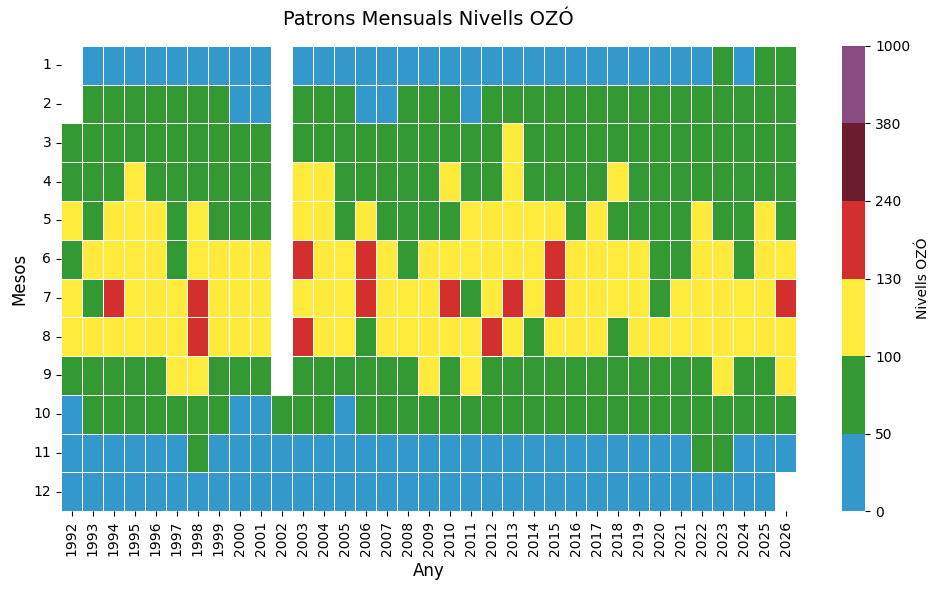

In [36]:
generar_mapa_calor(df_max_mensual, "OZÓ")

##🟢**Kruskal-Wallis + Post-hoc**

In [18]:

from scipy import stats

# Suposem que df té columnes: ['DATA', 'MUNICIPI', 'MAX_OZO_8h']
municipis = ["Barcelona", "Manresa", "Vic"]
df_sub = df[(df["MUNICIPI"].isin(municipis)) & (df["DATA"].dt.year.between(2011, 2026))].dropna(subset=["MAX_OZO_8h"]).copy()

# 1. Resum descriptiu robust (Mediana, IQR i Percentil 90)
resum = df_sub.groupby("MUNICIPI")["MAX_OZO_8h"].agg(
    dies="count",
    mediana="median",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
    p90=lambda x: x.quantile(0.90),
    maxim="max",
)
resum["IQR"] = resum["q75"] - resum["q25"]
print(resum.round(2))

# 2. Test global de Kruskal-Wallis
grups = [df_sub.loc[df_sub["MUNICIPI"] == m, "MAX_OZO_8h"] for m in municipis]
h_stat, p_kw = stats.kruskal(*grups)
print(f"\nKruskal-Wallis: H = {h_stat:.2f}, p-valor = {p_kw:.4e}")

# 3. Comparació per parelles (Mann-Whitney U + Bonferroni per 3 comparacions)
parelles = [("Vic", "Manresa"), ("Vic", "Barcelona"), ("Manresa", "Barcelona")]
for m1, m2 in parelles:
  g1 = df_sub.loc[df_sub["MUNICIPI"] == m1, "MAX_OZO_8h"]
  g2 = df_sub.loc[df_sub["MUNICIPI"] == m2, "MAX_OZO_8h"]
  u_stat, p_val = stats.mannwhitneyu(g1, g2, alternative="two-sided")
  p_adj = min(p_val * len(parelles), 1.0)
  dif_med = g1.median() - g2.median()
  print(
      f"{m1} vs {m2}: dif. medianes = {dif_med:+.2f} ug/m3 | p-valor ajustat ="
      f" {p_adj:.4e}"
  )

           dies  mediana    q25     q75     p90   maxim    IQR
MUNICIPI                                                      
Barcelona  5739    59.50  42.75   73.12   85.12  143.50  30.37
Manresa    5725    71.00  44.25   88.38  103.25  161.25  44.13
Vic        5767    82.25  56.88  103.50  123.12  194.25  46.62

Kruskal-Wallis: H = 1527.95, p-valor = 0.0000e+00
Vic vs Manresa: dif. medianes = +11.25 ug/m3 | p-valor ajustat = 4.0539e-96
Vic vs Barcelona: dif. medianes = +22.75 ug/m3 | p-valor ajustat = 0.0000e+00
Manresa vs Barcelona: dif. medianes = +11.50 ug/m3 | p-valor ajustat = 3.9700e-82


In [19]:
mesos_estiu = [ 6, 7, 8]
df_estiu = df_sub[df_sub["DATA"].dt.month.isin(mesos_estiu)].copy()

resum_estiu = df_estiu.groupby("MUNICIPI")["MAX_OZO_8h"].agg(
    dies="count",
    mediana="median",
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
    p90=lambda x: x.quantile(0.90),
    maxim="max",
)
resum_estiu["IQR"] = resum_estiu["q75"] - resum_estiu["q25"]
print(resum_estiu.round(2))

           dies  mediana    q25     q75     p90   maxim    IQR
MUNICIPI                                                      
Barcelona  1462    69.50  59.88   81.47   93.10  143.50  21.59
Manresa    1464    94.75  82.85  106.38  117.58  161.25  23.53
Vic        1471   112.75  97.75  129.88  142.00  194.25  32.13


/tmp/ipykernel_510/2852838225.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


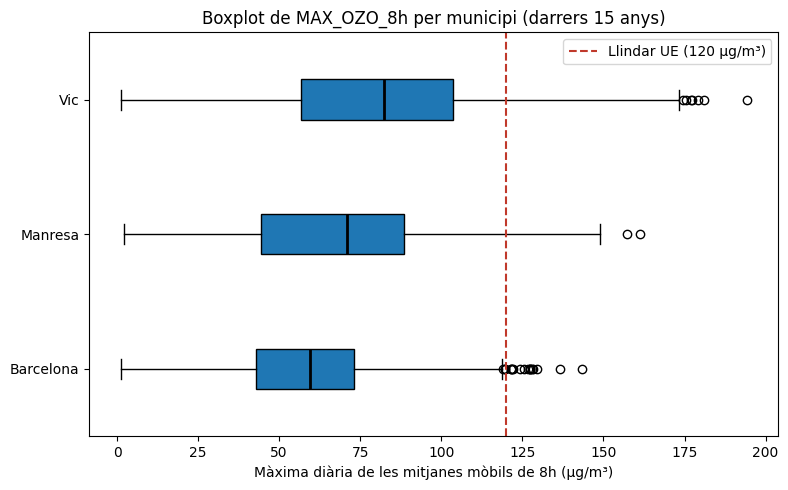

In [20]:
municipis = ["Barcelona", "Manresa", "Vic"]
dades = [
    df_sub.loc[df_sub["MUNICIPI"] == m, "MAX_OZO_8h"].dropna()
    for m in municipis
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(
    dades,
    vert=False,
    labels=municipis,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
)
ax.axvline(
    120,
    color="#C0392B",
    linestyle="--",
    linewidth=1.5,
    label="Llindar UE (120 µg/m³)",
)
ax.set_xlabel("Màxima diària de les mitjanes mòbils de 8h (µg/m³)")
ax.set_title("Boxplot de MAX_OZO_8h per municipi (darrers 15 anys)")
ax.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_510/4173293110.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


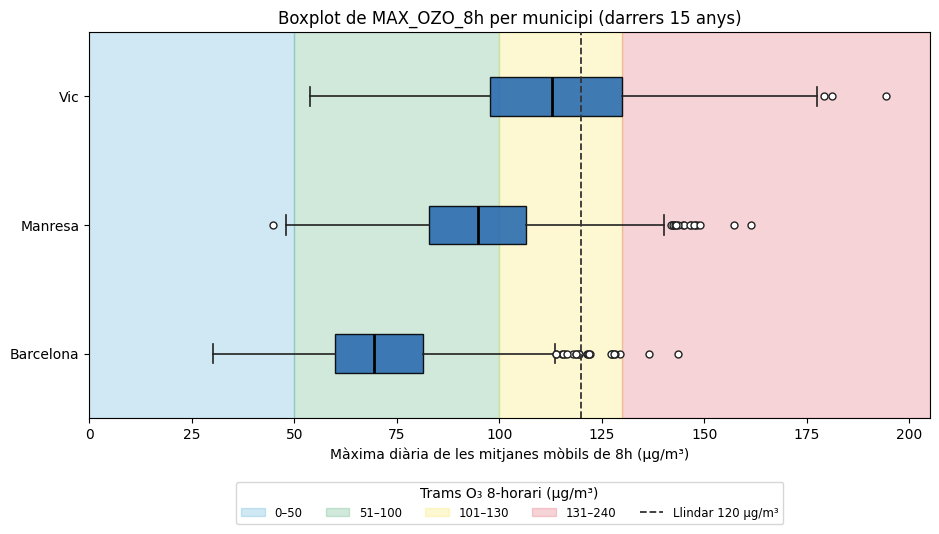

In [21]:
import matplotlib.pyplot as plt

mesos_estiu = [ 6, 7, 8]
#df_estiu = df_sub[df_sub["DATA"].dt.month.isin(mesos_estiu)].copy()
#     df_sub.loc[(df_sub["MUNICIPI"] == m) & (df_sub["DATA"].dt.month.isin(mesos_estiu)), "MAX_OZO_8h"].dropna()
#    df_sub.loc[df_sub["MUNICIPI"] == m, "MAX_OZO_8h"].dropna()

municipis = ["Barcelona", "Manresa", "Vic"]
dades = [
    df_sub.loc[(df_sub["MUNICIPI"] == m) & (df_sub["DATA"].dt.month.isin(mesos_estiu)), "MAX_OZO_8h"].dropna()
    for m in municipis
]

# Trams 8-horaris d'O3 (µg/m3) segons la taula de Catalunya: (inici, fi, etiqueta, color)
trams_8h = [
    (0, 50, "0–50", "#2998CC"),
    (50, 100, "51–100", "#2E9E5B"),
    (100, 130, "101–130", "#F7E336"),
    (130, 205, "131–240", "#D93B48"),
    # Si vols incloure trams superiors en ampliar l'eix X:
    #(240, 380, "241–380", "#6B0F1A"),
    #(380, 420, ">380", "#9B59B6"),
]

fig, ax = plt.subplots(figsize=(9.5, 5.5))

# 1. Franges de fons dels trams 8-horaris
for x0, x1, label, color in trams_8h:
  ax.axvspan(x0, x1, color=color, alpha=0.22, zorder=0, label=label)

# 2. Boxplot per sobre del fons
bp = ax.boxplot(
    dades,
    vert=False,
    labels=municipis,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="#222222", linewidth=1.2),
    capprops=dict(color="#222222", linewidth=1.2),
    flierprops=dict(
        marker="o",
        markersize=5,
        markerfacecolor="white",
        markeredgecolor="#222222",
    ),
    zorder=3,
)

for patch in bp["boxes"]:
  patch.set_facecolor("#2B6CB0")
  patch.set_edgecolor("black")
  patch.set_alpha(0.9)

# Línia de referència del llindar de 120 µg/m3 (dins del tram groc 101–130)
ax.axvline(
    120,
    color="#333333",
    linestyle="--",
    linewidth=1.3,
    zorder=4,
    label="Llindar 120 µg/m³",
)

ax.set_xlim(0, 205)
ax.set_xlabel("Màxima diària de les mitjanes mòbils de 8h (µg/m³)")
ax.set_title("Boxplot de MAX_OZO_8h per municipi (darrers 15 anys)")

ax.legend(
    title="Trams O₃ 8-horari (µg/m³)",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=5,
    frameon=True,
    fontsize=8.5,
)

plt.tight_layout()
plt.show()

##🟢**Comparar proporcions de superacio: Khi quadrat**

In [22]:
municipis = ["Barcelona", "Manresa", "Vic"]
df_llindar = df[(df["MUNICIPI"].isin(municipis)) & (df["DATA"].dt.year.between(2011, 2026))].dropna(subset=["SUPERA_LIMIT_UE", "MUNICIPI"]).copy()
df_llindar["SUPERA_LIMIT_UE"] = df_llindar["SUPERA_LIMIT_UE"].astype(int)

# Taula de contingència: files = ZONA, columnes = 0 (no supera) / 1 (supera)
taula = pd.crosstab(df_llindar["MUNICIPI"], df_llindar["SUPERA_LIMIT_UE"])
print(taula)

chi2, p_chi2, dof, ex = stats.chi2_contingency(taula)
print(f"Khi-quadrat: chi2={chi2:.2f}, gl={dof}, p-valor={p_chi2:.4e}")

SUPERA_LIMIT_UE     0    1
MUNICIPI                  
Barcelona        5724   15
Manresa          5606  119
Vic              5105  662
Khi-quadrat: chi2=947.14, gl=2, p-valor=2.1461e-206


##🟢**Número hores a cada nivell de la EEA**

In [23]:
df_qualitat.groupby(["CODI_EOI"]).size()

,0
CODI_EOI,
08019043,242760
08112003,138528
08113007,301176
08283002,31512
08283004,150672
08298007,84312
08298008,210120


/tmp/ipykernel_510/2484376906.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


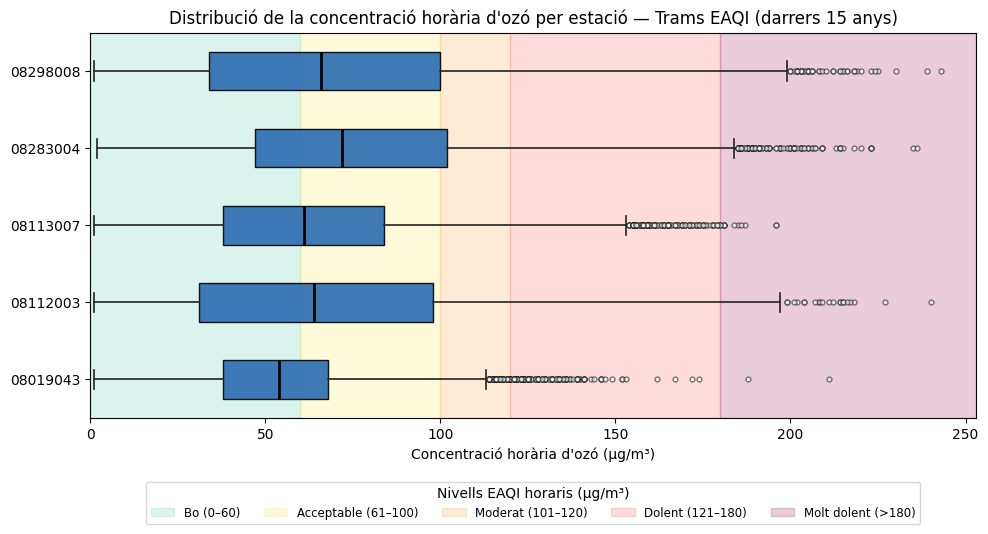

In [24]:


# 1. Preparem les dades horàries (darrers 15 anys)

df_h = df_qualitat.copy()
df_h["DATA"] = pd.to_datetime(df_h["DATA"])
df_h = df_h[df_h["DATA"].dt.year >= 2011].dropna(subset=["VALUE"])

# Si vols filtrar només estiu:
df_h = df_h[df_h["DATA"].dt.month.isin([6, 7, 8])]

estacions = sorted(df_h["CODI_EOI"].unique())
dades = [
    df_h.loc[df_h["CODI_EOI"] == e, "VALUE"].values for e in estacions
]

# 2. Franges EAQI horàries per a O3 (µg/m3): (inici, fi, etiqueta, color)
xmax = max(200, df_h["VALUE"].max() + 10)
franges_eea_horaries = [
    (0, 60, "Bo (0–60)", "#50CCAA"),
    (60, 100, "Acceptable (61–100)", "#F0E641"),
    (100, 120, "Moderat (101–120)", "#FF9933"),
    (120, 180, "Dolent (121–180)", "#FF5050"),
    (180, xmax, "Molt dolent (>180)", "#99004C"),
]

fig, ax = plt.subplots(figsize=(10, 5.5))

# Pintem les franges al fons
for x0, x1, label, color in franges_eea_horaries:
  ax.axvspan(x0, x1, color=color, alpha=0.20, zorder=0, label=label)

# Boxplot horitzontal de concentració horària
bp = ax.boxplot(
    dades,
    vert=False,
    labels=estacions,
    patch_artist=True,
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="#222222", linewidth=1.2),
    capprops=dict(color="#222222", linewidth=1.2),
    flierprops=dict(
        marker="o",
        markersize=3.5,
        markerfacecolor="white",
        markeredgecolor="#222222",
        alpha=0.6,
    ),
    zorder=3,
)

for patch in bp["boxes"]:
  patch.set_facecolor("#2B6CB0")
  patch.set_edgecolor("black")
  patch.set_alpha(0.9)

ax.set_xlim(0, xmax)
ax.set_xlabel("Concentració horària d'ozó (µg/m³)")
ax.set_title(
    "Distribució de la concentració horària d'ozó per estació — Trams EAQI"
    " (darrers 15 anys)"
)
ax.legend(
    title="Nivells EAQI horaris (µg/m³)",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=5,
    frameon=True,
    fontsize=8.5,
)

plt.tight_layout()
plt.show()


In [25]:


# 1. Preparem dades horàries (darrers 15 anys)
df_h = df_qualitat.copy()
df_h["DATA"] = pd.to_datetime(df_h["DATA"])
df_h = df_h[df_h["DATA"].dt.year >= 2011].dropna(subset=["VALUE"])
df_h["ANY"] = df_h["DATA"].dt.year

# 2. Filtrem NOMÉS les hores en trams no aconsellats (> 100 µg/m3)
df_alt = df_h[df_h["VALUE"] > 100].copy()
bins = [100, 120, 180, float("inf")]
labels = ["Moderat (101–120)", "Dolent (121–180)", "Molt dolent (>180)"]
df_alt["TRAM_ALT"] = pd.cut(
    df_alt["VALUE"], bins=bins, labels=labels, right=True
)

# 3. Calculem la mitjana d'hores/any per estació i tram (incloent anys amb 0)
estacions = sorted(df_h["CODI_EOI"].unique())
anys = sorted(df_h["ANY"].unique())

hores_anuals = (
    df_alt.groupby(["CODI_EOI", "ANY", "TRAM_ALT"], observed=False)
    .size()
    .unstack(fill_value=0)
    .reindex(
        pd.MultiIndex.from_product(
            [estacions, anys], names=["CODI_EOI", "ANY"]
        ),
        fill_value=0,
    )
)

mitjana_anual = hores_anuals.groupby("CODI_EOI").mean()
mitjana_anual



TRAM_ALT,Moderat (101–120),Dolent (121–180),Molt dolent (>180)
CODI_EOI,,,
08019043,72.9375,10.6875,0.1250
08112003,473.7500,264.5625,4.9375
08113007,274.6250,99.5625,0.6250
08283004,552.7500,347.8750,9.3125
08298008,522.5000,333.8750,11.1875


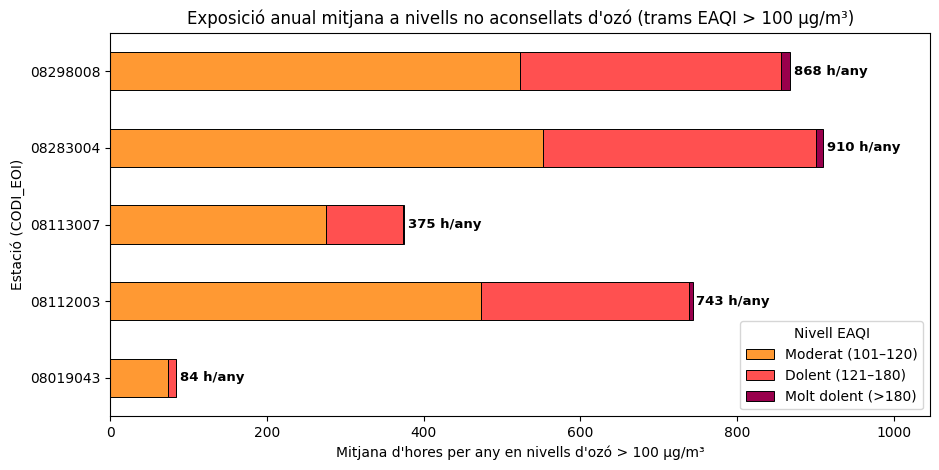

In [26]:

# 4. Gràfic de barres horitzontals apilades amb els colors oficials EAQI
colors_eaqi = ["#FF9933", "#FF5050", "#99004C"]
ax = mitjana_anual.plot(
    kind="barh",
    stacked=True,
    color=colors_eaqi,
    figsize=(9.5, 4.8),
    edgecolor="black",
    linewidth=0.7,
)

# Afegim el total d'hores >100 al final de cada barra
totals = mitjana_anual.sum(axis=1)
for i, total in enumerate(totals):
  ax.text(
      total + 5,
      i,
      f"{total:.0f} h/any",
      va="center",
      fontweight="bold",
      fontsize=9.5,
  )

ax.set_xlim(0, totals.max() * 1.15)
ax.set_xlabel("Mitjana d'hores per any en nivells d'ozó > 100 µg/m³")
ax.set_ylabel("Estació (CODI_EOI)")
ax.set_title(
    "Exposició anual mitjana a nivells no aconsellats d'ozó (trams EAQI > 100"
    " µg/m³)"
)
ax.legend(title="Nivell EAQI", loc="lower right", frameon=True)
plt.tight_layout()
plt.show()